In [1]:
import torch
import torch.nn as nn
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, ControlNetModel
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

# --- ローカルGPUの設定 ---
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

/home/masaki/anaconda3/envs/mystudy/lib/python3.9/site-packages/accelerate/utils/torch_xla.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


Using device: cuda


In [2]:
#モデルの再定義と「最高の重み」の読み込み
# ===================================================================
# 学習時と全く同じモデルクラスを再定義
# ===================================================================
class CustomConditionalLDM(nn.Module):
    # (02_model_training.ipynbで使った【最終決定版】のクラス定義をここにコピー＆ペースト)
    def __init__(self, pretrained_model_name="runwayml/stable-diffusion-v1-5"):
        super().__init__()
        
        self.vae = AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae")
        self.tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
        self.text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder")
        self.unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet")
        self.scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
        self.controlnet = ControlNetModel.from_config(self.unet.config)
        
        # ★★★ The Final, Crucial Fix ★★★
        # Replace the default conditioning embedding with a simple one that matches the shapes.
        # This ensures the "highway" and the "on-ramp" have the same number of lanes.
        in_channels = 4 # VAE latent has 4 channels
        out_channels = self.controlnet.conv_in.out_channels # Match the main U-Net input channels (e.g., 320)
        
        self.controlnet.controlnet_cond_embedding = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        )
        # Initialize the new part with zeros for stable training (Zero Convolution)
        for module in self.controlnet.controlnet_cond_embedding.modules():
            if isinstance(module, nn.Conv2d):
                torch.nn.init.zeros_(module.weight)
                torch.nn.init.zeros_(module.bias)

        # Freeze the parts we are not training
        self.vae.requires_grad_(False)
        self.text_encoder.requires_grad_(False)
        self.unet.requires_grad_(False)
        
        print("✅ CustomConditionalLDM model initialized with FINAL architecture.")
        print("   - VAE, Text Encoder, and U-Net are FROZEN.")
        print("   - Only the ControlNet is TRAINABLE.")

    def forward(self, batch):
        # ... (the forward function does not need to change) ...
        baseline_images = batch["baseline_image"]
        future_images = batch["future_image"]
        condition_labels = batch["condition_label"]

        with torch.no_grad():
            baseline_latents = self.vae.encode(baseline_images).latent_dist.sample() * self.vae.config.scaling_factor
            future_latents = self.vae.encode(future_images).latent_dist.sample() * self.vae.config.scaling_factor
            
        noise = torch.randn_like(future_latents)
        timesteps = torch.randint(0, self.scheduler.config.num_train_timesteps, (future_latents.shape[0],), device=future_latents.device).long()
        noisy_future_latents = self.scheduler.add_noise(future_latents, noise, timesteps)

        with torch.no_grad():
            text_input = self.tokenizer(condition_labels, padding="max_length", max_length=self.tokenizer.model_max_length, truncation=True, return_tensors="pt")
            text_embeddings = self.text_encoder(text_input.input_ids.to(self.unet.device))[0]

        down_block_res_samples, mid_block_res_sample = self.controlnet(
            noisy_future_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            controlnet_cond=baseline_latents,
            return_dict=False,
        )

        predicted_noise = self.unet(
            noisy_future_latents,
            timesteps,
            encoder_hidden_states=text_embeddings,
            down_block_additional_residuals=down_block_res_samples,
            mid_block_additional_residual=mid_block_res_sample
        ).sample

        return predicted_noise, noise
        
# ===================================================================
# モデルのインスタンス化と重みの読み込み
# ===================================================================
print("Initializing the model structure...")
model = CustomConditionalLDM().to(device)

# --- ★★★ ここが最重要 ★★★ ---
# 学習したControlNetの「最高の重み」を読み込む
CONTROLNET_WEIGHTS_PATH = '/home/masaki/mystudy/trained_models/best_model_epoch_50.pth'
model.controlnet.load_state_dict(torch.load(CONTROLNET_WEIGHTS_PATH, map_location=device))
model.eval() # モデルを推論モードに設定

print(f"✅ Best model weights loaded from: {CONTROLNET_WEIGHTS_PATH}")

Initializing the model structure...
✅ CustomConditionalLDM model initialized with FINAL architecture.
   - VAE, Text Encoder, and U-Net are FROZEN.
   - Only the ControlNet is TRAINABLE.
✅ Best model weights loaded from: /home/masaki/mystudy/trained_models/best_model_epoch_50.pth


In [3]:
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import pandas as pd
from torchvision import transforms
import nibabel as nib
import os

# ===================================================================
# データセットクラスも再定義が必要 (正規化処理を修正)
# ===================================================================
class BrainMetsDataset(Dataset):
    """
    【完成版】
    推論用に、ベースライン画像だけを正しく前処理して読み込むクラス。
    """
    def __init__(self, csv_file, image_root_dir, patient_ids, mode, image_size=256):
        self.data = pd.read_csv(csv_file)
        self.data = self.data[self.data['PatientID'].isin(patient_ids)]
        self.image_root_dir = image_root_dir
        self.mode = mode
        self.scans = self._get_scans()
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((image_size, image_size), antialias=True),
            transforms.Normalize([0.5], [0.5])
        ])

    def _get_scans(self):
        scans = []
        baseline_scans = self.data[self.data['FinalPattern'] == 'Baseline']
        for _, baseline_row in baseline_scans.iterrows():
            scans.append(baseline_row.to_dict())
        print(f"Found {len(scans)} baseline images for '{self.mode}' set.")
        return scans

    def __len__(self):
        return len(self.scans)

    def __getitem__(self, idx):
        scan_info = self.scans[idx]
        base_name_without_ext = scan_info['FileName'].replace('.nii.gz', '')
        filename_with_suffix = f"{base_name_without_ext}_0000.nii.gz"
        path = os.path.join(self.image_root_dir, filename_with_suffix)
        
        try:
            nii_img = nib.load(path)
            data = nii_img.get_fdata().astype('float32')
            slice_img = data[:, :, data.shape[2] // 2]

            # ★★★ ここが最重要の修正点 ★★★
            # 1. まず、スライス内のピクセル値を0から1の範囲に正規化する
            if slice_img.max() > slice_img.min():
                slice_img = (slice_img - slice_img.min()) / (slice_img.max() - slice_img.min())
            
            # 2. その後、PyTorchのtransformを適用する
            image = self.transform(slice_img)
            
            # グレースケール画像を3回繰り返して3チャンネルにする
            image = image.repeat(3, 1, 1)
            
            return {"baseline_image": image, "patient_id": scan_info['PatientID']}
        
        except FileNotFoundError:
            print(f"Warning: File not found {path}. Skipping.")
            return self.__getitem__((idx + 1) % len(self))


# ===================================================================
# テストデータの準備 (この部分は変更なし)
# ===================================================================
IMAGE_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'
CSV_FILE = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
full_df = pd.read_csv(CSV_FILE)
patient_ids = full_df['PatientID'].unique()
_, temp_patient_ids = train_test_split(patient_ids, test_size=0.3, random_state=42)
_, test_patient_ids = train_test_split(temp_patient_ids, test_size=0.5, random_state=42)

test_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=test_patient_ids, mode='test')
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

try:
    sample_batch = next(iter(test_dataloader))
    baseline_image = sample_batch["baseline_image"].to(device)
    patient_id = sample_batch["patient_id"][0]
    print(f"\nLoaded baseline image for patient: {patient_id}")
except StopIteration:
    print("❌ Test dataset is empty. Check your data splitting logic.")

Found 205 baseline images for 'test' set.

Loaded baseline image for patient: YG_XTE7MC3SRI1E



Generating future image for condition: 'Progression'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising:   0%|          | 0/50 [00:00<?, ?it/s]

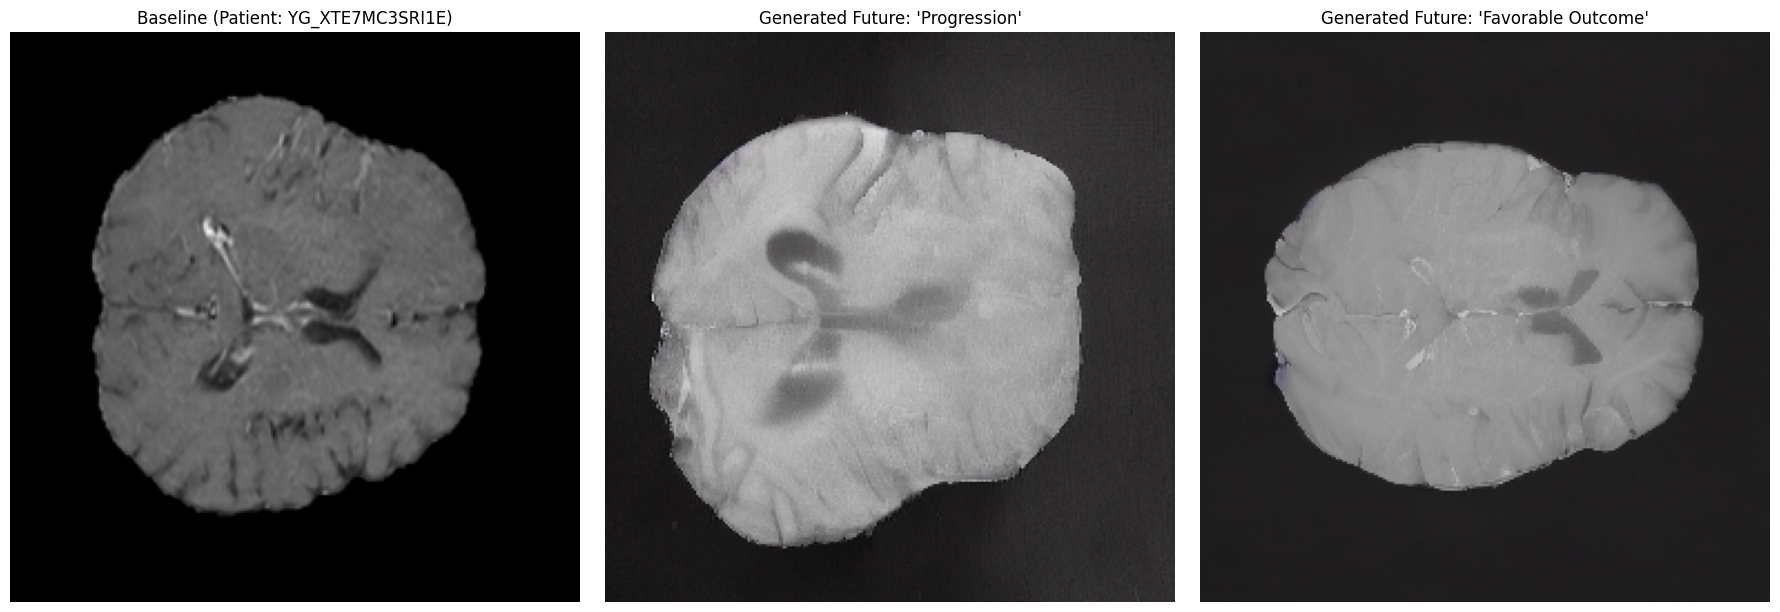

In [4]:
from diffusers import DDPMScheduler # Schedulerもインポートが必要です
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ===================================================================
# 推論（画像生成）を行う関数
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50):
    """
    与えられたベースライン画像と条件から、未来の画像を生成する関数。
    """
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    
    # --- 1. 条件の準備 ---
    # モデルを推論モードに設定
    model.eval()
    with torch.no_grad(): # 推論時は勾配計算は不要
        # ベースライン画像をVAEで潜在表現に変換
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        
        # テキストラベルを数値ベクトルに変換
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    # --- 2. 推論ループの準備 ---
    # ノイズ除去のスケジュールを設定
    model.scheduler.set_timesteps(num_inference_steps)
    # 生成の出発点となる、純粋なノイズを準備
    latents = torch.randn_like(baseline_latents)

    # --- 3. ノイズ除去ループ (サンプリング) ---
    # 彫刻家が石の塊から少しずつ形を掘り出すように、ノイズから画像を復元していく
    for t in tqdm(model.scheduler.timesteps, desc="Denoising"):
        with torch.no_grad():
            # ControlNetで制御信号（画像の構造）を生成
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            # U-Netで、現在の画像から取り除くべきノイズを予測
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        
        # Schedulerを使って、予測されたノイズを少しだけ取り除き、1ステップ前の画像を計算
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    # --- 4. VAEで最終的な画像を復元 ---
    with torch.no_grad():
        # スケールを元に戻す
        latents = 1 / model.vae.config.scaling_factor * latents
        # 潜在表現をピクセル画像にデコード（解凍）
        image = model.vae.decode(latents).sample
        
    # 画像を0-255のPIL.Image形式に変換
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# --- 2つの条件で画像を生成 ---
progression_image = generate_future_image(model, baseline_image, "Progression")
favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")

# ===================================================================
# 結果の可視化
# ===================================================================
# 元のベースライン画像も表示用にPIL.Image形式に変換する関数
def to_pil(tensor_image):
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

# 3枚の画像を並べて表示
plt.figure(figsize=(18, 6))
plt.subplot(1, 3, 1)
plt.imshow(to_pil(baseline_image), cmap='gray')
plt.title(f"Baseline (Patient: {patient_id})")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(progression_image, cmap='gray')
plt.title("Generated Future: 'Progression'")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(favorable_image, cmap='gray')
plt.title("Generated Future: 'Favorable Outcome'")
plt.axis('off')

plt.tight_layout()
plt.show()